In [20]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats

sys.path.insert(0, os.path.abspath("../src"))
from new_data import create_new_data

# Leitura do Conjunto de Dados

In [21]:
raiz = os.path.dirname(os.getcwd()) #pega o caminho da pasta raiz do projeto
print(raiz)

pasta = os.path.join(raiz, "DATA", "CSV_regioes") # viaja até a pasta que contém os CSV

lista_dfs = []

# Lê todos os arquivos CSV da pasta
for ficheiro in sorted(os.listdir(pasta)):
    if ficheiro.endswith(".csv"):
        caminho_csv = os.path.join(pasta, ficheiro)
        # Lê o CSV individual
        dados_ano = pd.read_csv(caminho_csv, sep=";")
        # Adiciona na lista
        lista_dfs.append(dados_ano)

# Concatena (junta) todas as tabelas em um único DataFrame
df_completo = pd.concat(lista_dfs, ignore_index=True)

# Visualiza as informações
print(f"Total de linhas combinadas: {len(df_completo)}")
display(df_completo)

c:\Users\Rebeca\Área de Trabalho\PRCP_RDA_ANALISIS
Total de linhas combinadas: 750321


,data,lat,lon,precip_mm,municipio,estado,uf,regiao
0,2006-01-01,-7.75,-41.25,5.292850,Jacobina do Piauí,Piauí,PI,Nordeste
1,2006-01-01,-7.75,-40.75,10.205985,Simões,Piauí,PI,Nordeste
2,2006-01-01,-7.75,-40.25,20.805733,Trindade,Pernambuco,PE,Nordeste
3,2006-01-01,-7.75,-39.75,6.968030,Granito,Pernambuco,PE,Nordeste
4,2006-01-01,-7.75,-39.25,0.812125,Cedro,Pernambuco,PE,Nordeste
...,...,...,...,...,...,...,...,...
750316,2026-09-29,-2.75,-39.25,NaN,NaN,NaN,NaN,NaN
750317,2026-09-29,-2.75,-38.75,NaN,NaN,NaN,NaN,NaN
750318,2026-09-29,-2.75,-38.25,NaN,NaN,NaN,NaN,NaN
750319,2026-09-29,-2.75,-37.75,NaN,NaN,NaN,NaN,NaN


In [22]:
df_completo.describe()

,lat,lon,precip_mm
count,750321.00000,750321.000000,666864.000000
mean,-5.25000,-39.250000,21.461001
std,1.58114,1.290995,59.904140
min,-7.75000,-41.250000,0.000000
25%,-6.75000,-40.250000,0.000000
50%,-5.25000,-39.250000,0.000000
75%,-3.75000,-38.250000,10.014323
max,-2.75000,-37.250000,1634.727295


In [23]:
df_completo.columns

Index(['data', 'lat', 'lon', 'precip_mm', 'municipio', 'estado', 'uf',
       'regiao'],
      dtype='str')

In [24]:
"""
.isna() é um método do pandas que retorna um DataFrame booleano
indicando a presença de valores ausentes (NaN) em cada célula do
DataFrame original. Se uma célula contém um valor ausente, o 
resultado será True; caso contrário, será False.
"""
df_completo.isna()

,data,lat,lon,precip_mm,municipio,estado,uf,regiao
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...
750316,False,False,False,True,True,True,True,True
750317,False,False,False,True,True,True,True,True
750318,False,False,False,True,True,True,True,True
750319,False,False,False,True,True,True,True,True


In [25]:
"""
Seguindo a lógica do método .isna(), o método .sum() é aplicado ao DataFrame booleano resultante.
O método .sum() soma os valores True (que são tratados como 1) em cada coluna,
fornecendo o total de valores ausentes (NaN) em cada coluna do DataFrame original.
"""
df_completo.isna().sum()

data             0
lat              0
lon              0
precip_mm    83457
municipio    90948
estado       90948
uf           90948
regiao       90948
dtype: int64

In [26]:
"""
Retorna os tipos de dados de cada coluna do DataFrame.
Isso é útil para entender a estrutura dos dados e identi-
ficar possíveis problemas de tipo.
"""
df_completo.dtypes

data             str
lat          float64
lon          float64
precip_mm    float64
municipio        str
estado           str
uf               str
regiao           str
dtype: object

In [27]:
df_completo.info()

<class 'pandas.DataFrame'>
RangeIndex: 750321 entries, 0 to 750320
Data columns (total 8 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   data       750321 non-null  str    
 1   lat        750321 non-null  float64
 2   lon        750321 non-null  float64
 3   precip_mm  666864 non-null  float64
 4   municipio  659373 non-null  str    
 5   estado     659373 non-null  str    
 6   uf         659373 non-null  str    
 7   regiao     659373 non-null  str    
dtypes: float64(3), str(5)
memory usage: 70.5 MB


In [28]:
# Criando Variável Qualitativa Ordinal: Categorias de Precipitacoes
condicoes = [
    (df_completo['precip_mm'] == 0),
    (df_completo['precip_mm'] > 0) & (df_completo['precip_mm'] <= 5),
    (df_completo['precip_mm'] > 5) & (df_completo['precip_mm'] <= 25),
    (df_completo['precip_mm'] > 25),
]
rotulos = ['Sem Precipitação', 'Fraca', 'Moderada', 'Forte']
df_completo['classe_chuva'] = np.select(condicoes, rotulos, default='Sem Preciptação')

display(df_completo)

,data,lat,lon,precip_mm,municipio,estado,uf,regiao,classe_chuva
0,2006-01-01,-7.75,-41.25,5.292850,Jacobina do Piauí,Piauí,PI,Nordeste,Moderada
1,2006-01-01,-7.75,-40.75,10.205985,Simões,Piauí,PI,Nordeste,Moderada
2,2006-01-01,-7.75,-40.25,20.805733,Trindade,Pernambuco,PE,Nordeste,Moderada
3,2006-01-01,-7.75,-39.75,6.968030,Granito,Pernambuco,PE,Nordeste,Moderada
4,2006-01-01,-7.75,-39.25,0.812125,Cedro,Pernambuco,PE,Nordeste,Fraca
...,...,...,...,...,...,...,...,...,...
750316,2026-09-29,-2.75,-39.25,NaN,NaN,NaN,NaN,NaN,Sem Preciptação
750317,2026-09-29,-2.75,-38.75,NaN,NaN,NaN,NaN,NaN,Sem Preciptação
750318,2026-09-29,-2.75,-38.25,NaN,NaN,NaN,NaN,NaN,Sem Preciptação
750319,2026-09-29,-2.75,-37.75,NaN,NaN,NaN,NaN,NaN,Sem Preciptação


# Estatística Descritiva

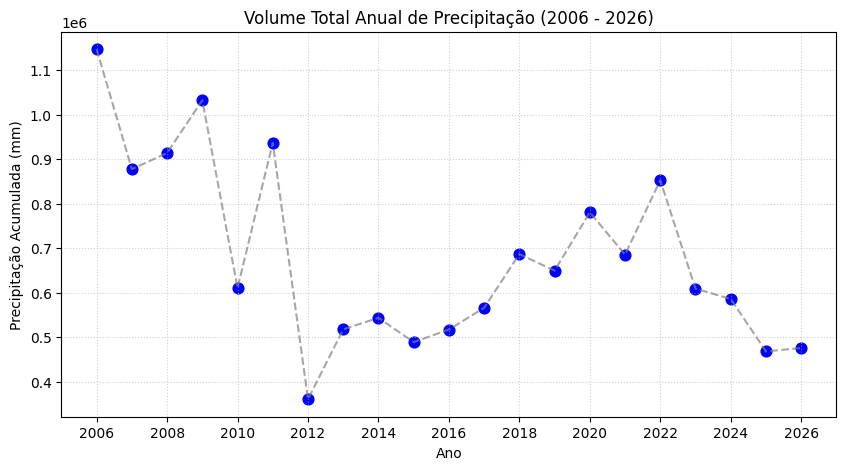

In [29]:
# 1. Garantir que a coluna de data está no formato correto
df_completo['data'] = pd.to_datetime(df_completo['data'])

# 2. Criar a coluna de Ano
df_completo['ano'] = df_completo['data'].dt.year

# 3. Calcular o volume total de chuva por ano
total_anual = df_completo.groupby('ano')['precip_mm'].sum().reset_index()

# 4. Gráfico de dispersão (Scatter Plot) ou Linha Anual
plt.figure(figsize=(10, 5))
plt.scatter(total_anual['ano'], total_anual['precip_mm'], color='blue', s=60)
plt.plot(
    total_anual['ano'],
    total_anual['precip_mm'],
    linestyle='--',
    color='gray',
    alpha=0.7,
)

plt.title('Volume Total Anual de Precipitação (2006 - 2026)')
plt.xlabel('Ano')
plt.ylabel('Precipitação Acumulada (mm)')
plt.xticks(range(2006, 2027, 2))  # Exibe de 2 em 2 anos no eixo X
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

## DISTRIBUICAO DE FREQUENCIA

### 1.2 UNIVARIAVEL

Tabela de frequencias para variáveis quantitativas

In [75]:
df_completo["precip_mm"].value_counts(sort=False, bins=15)

(-1.636, 108.982]       626511
(108.982, 217.964]       26683
(217.964, 326.945]        8345
(326.945, 435.927]        3121
(435.927, 544.909]        1275
(544.909, 653.891]         545
(653.891, 762.873]         231
(762.873, 871.855]          92
(871.855, 980.836]          39
(980.836, 1089.818]         13
(1089.818, 1198.8]           7
(1198.8, 1307.782]           1
(1307.782, 1416.764]         0
(1416.764, 1525.745]         0
(1525.745, 1634.727]         1
Name: count, dtype: int64

Tabela de frequencias para variáveis qualitativas

In [76]:
def tabel_freq_quali(column):
    freq_abs = column.value_counts()
    freq_rel = column.value_counts(normalize=True)

    tabela = pd.DataFrame({
        "Freq absoluta": freq_abs,
        "Freq relativa": freq_rel,
        "Freq relativa (%)": freq_rel * 100,
    })
    tabela.index.name = column.name
    return tabela.reset_index()

col_qualitativas = ["estado", "municipio", "uf", "regiao"]

for i in col_qualitativas:
    print(f"\n-> {i}")
    print(tabel_freq_quali(df_completo[i]).to_string(index=False))


-> estado
             estado  Freq absoluta  Freq relativa  Freq relativa (%)
              Ceará         424424       0.643678          64.367816
              Piauí          83369       0.126437          12.643678
            Paraíba          53053       0.080460           8.045977
Rio Grande do Norte          53053       0.080460           8.045977
         Pernambuco          45474       0.068966           6.896552

-> municipio
                 municipio  Freq absoluta  Freq relativa  Freq relativa (%)
               Jaguaretama          15158       0.022989           2.298851
                Boa Viagem          15158       0.022989           2.298851
         Jacobina do Piauí           7579       0.011494           1.149425
                    Simões           7579       0.011494           1.149425
                  Trindade           7579       0.011494           1.149425
                   Granito           7579       0.011494           1.149425
                     Cedro   

Gráficos

<Axes: xlabel='Intervalo'>

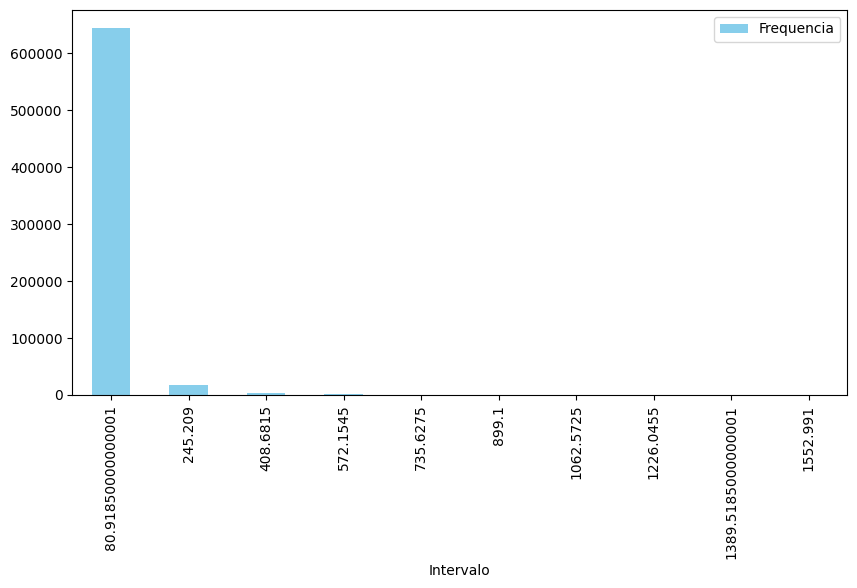

In [31]:
freq_i = df_completo["precip_mm"].value_counts(sort=False, bins=10)

freq_i_data = pd.DataFrame({
    "Intervalo" : freq_i.index.mid,
    "Frequencia" : freq_i.values
})

freq_i_data.plot(x="Intervalo", y="Frequencia", kind="bar", figsize=(10, 5), color='skyblue')

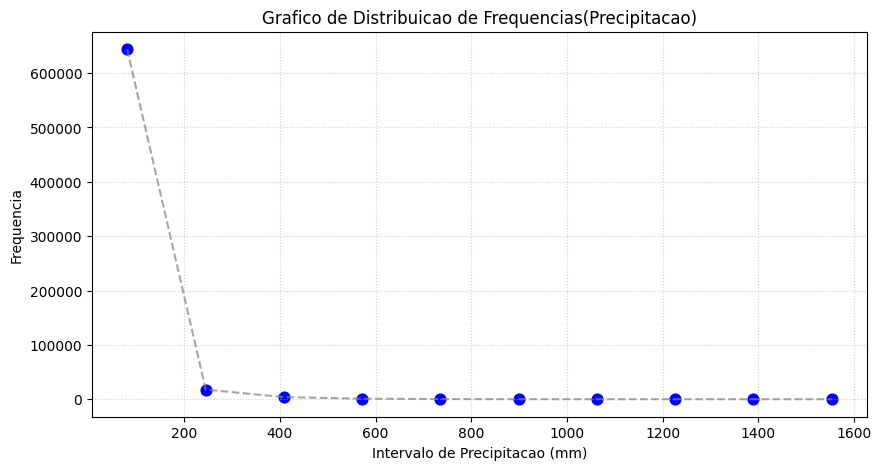

In [32]:
freq_i = df_completo["precip_mm"].value_counts(sort=False, bins=10)

freq_i_data = pd.DataFrame({
    "Intervalo" : freq_i.index.mid,
    "Frequencia" : freq_i.values
})

plt.figure(figsize=(10, 5))
plt.scatter(freq_i_data['Intervalo'], freq_i_data['Frequencia'], color='blue', s=60)
plt.plot(
    freq_i_data['Intervalo'],
    freq_i_data['Frequencia'],
    linestyle='--',
    color='gray',
    alpha=0.7,
)

plt.title('Grafico de Distribuicao de Frequencias(Precipitacao)')
plt.xlabel('Intervalo de Precipitacao (mm)')
plt.ylabel('Frequencia')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### 1.2 BIVARIAVEL

### 1.4 MEDIDA DE POSICAO

In [33]:
def medida_posicao(df: pd.DataFrame):
    """
    Calcula medidas de posição para a coluna 'precip_mm', maiores que zero, do DataFrame fornecido.
    
    Parâmetros:
    df (pd.DataFrame): DataFrame contendo a coluna 'precip_mm'.
    
    Retorna:
    dict: Um dicionário contendo as medidas de posição.
    """
    chuva = df_completo.loc[df_completo["precip_mm"] > 0, "precip_mm"]

    media = chuva.mean()
    mediana = chuva.median()
    moda = chuva.mode()[0]  # Pega o primeiro valor da moda
    minimo = chuva.min()
    maximo = chuva.max()
    
    return {
        "Média": media,
        "Mediana": mediana,
        "Moda": moda,
        "Mínimo": minimo,
        "Máximo": maximo
    }

In [34]:
def medida_dispersao(df: pd.DataFrame):
    """
    Calcula medidas de dispersão para a coluna 'precip_mm', maiores que zero, do DataFrame fornecido.
    
    Parâmetros:
    df (pd.DataFrame): DataFrame contendo a coluna 'precip_mm'.
    
    Retorna:
    dict: Um dicionário contendo as medidas de dispersão.
    """
    chuva = df_completo.loc[df_completo["precip_mm"] > 0, "precip_mm"]

    variancia = chuva.mean()
    mediana = chuva.median()
    moda = chuva.mode()[0]  # Pega o primeiro valor da moda
    minimo = chuva.min()
    maximo = chuva.max()
    
    return {
        "Média": media,
        "Mediana": mediana,
        "Moda": moda,
        "Mínimo": minimo,
        "Máximo": maximo
    }

In [35]:
medidas_posicao = medida_posicao(df_completo)
print("Medidas de Posição para a coluna 'precip_mm':")
for medida, valor in medidas_posicao.items():
    print(f"{medida}: {valor}")

Medidas de Posição para a coluna 'precip_mm':
Média: 48.98001553287524
Mediana: 15.33854150772095
Moda: 0.2985477447509766
Mínimo: 0.0286579076200723
Máximo: 1634.727294921875


Medidas de posicao para variaveis qualitativas

In [ ]:
def iqv(freq):
    k = freq.value_counts(normalize=True)
    n = len(k)
    if n < 2:
        return 0

    iqv_value = (n / (n - 1)) * (1 - (k**2).sum())
    return iqv_value


In [60]:
iqv_estado = iqv(df_completo["estado"])
iqv_municipio = iqv(df_completo["municipio"])
iqv_uf = iqv(df_completo["uf"])
iqv_regiao = iqv(df_completo["regiao"])
iqv_precip_mm = iqv(df_completo["precip_mm"])

tabela_iqv = pd.DataFrame({
    "Variável": ["estado", "municipio", "uf", "regiao", "precip_mm"],
    "IQV" : [iqv_estado, iqv_municipio, iqv_uf, iqv_regiao, iqv_precip_mm]
})

print(tabela_iqv)

    Variável       IQV
0     estado  0.689985
1  municipio  0.999739
2         uf  0.689985
3     regiao  0.000000
4  precip_mm  0.684336
